In [ ]:
from google.colab import files
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

In [ ]:
# Load patients data
d1 = files.upload()
patients = pd.read_csv('PATIENTS.csv.gz')

Saving PATIENTS.csv.gz to PATIENTS.csv.gz


In [ ]:
# Load admissions data
d2 = files.upload()
admissions = pd.read_csv('ADMISSIONS.csv.gz')

Saving ADMISSIONS.csv.gz to ADMISSIONS.csv.gz


In [ ]:
# Load diagnoses_icd data
d3 = files.upload()
diagnoses = pd.read_csv('DIAGNOSES_ICD.csv.gz')

Saving DIAGNOSES_ICD.csv.gz to DIAGNOSES_ICD.csv.gz


In [ ]:
# Load ICUSTAYS data
d4 = files.upload()
icustays = pd.read_csv('ICUSTAYS.csv.gz')

Saving ICUSTAYS.csv.gz to ICUSTAYS.csv.gz


In [ ]:
# Load D_ICD_DIAGNOSES data
d4 = files.upload()
diagnoses_labels = pd.read_csv('D_ICD_DIAGNOSES.csv.gz')

Saving D_ICD_DIAGNOSES.csv.gz to D_ICD_DIAGNOSES.csv.gz


In [ ]:
# Make column names lowercase
for df in [patients, admissions, diagnoses, icustays, diagnoses_labels]:
    df.columns = df.columns.str.lower()

# Convert dates
patients["dob"] = pd.to_datetime(patients["dob"], errors="coerce")

admissions["admittime"] = pd.to_datetime(
    admissions["admittime"], errors="coerce"
)
admissions["dischtime"] = pd.to_datetime(
    admissions["dischtime"], errors="coerce"
)

icustays["intime"] = pd.to_datetime(
    icustays["intime"], errors="coerce"
)
icustays["outtime"] = pd.to_datetime(
    icustays["outtime"], errors="coerce"
)

# Build an admission-level analysis table
adm = admissions.merge(
    patients[["subject_id", "gender", "dob"]],
    on="subject_id",
    how="left"
)

# Age AT HOSPITAL ADMISSION
# Pandas default Timedelta unit is nanoseconds.
# Calculate age in days first to avoid OverflowError with very large time differences,
# then convert to years.
time_diff_days = (adm["admittime"].values - adm["dob"].values).astype('timedelta64[D]')
adm["age"] = time_diff_days.astype('float') / 365.2425

# In MIMIC-III exact ages above 89 are de-identified.
# Treat them as a "90+" group for these visualizations.
adm.loc[adm["age"] > 89, "age"] = 90

# Hospital length of stay in days
adm["hospital_los_days"] = (
    adm["dischtime"] - adm["admittime"]
).dt.total_seconds() / (24 * 60 * 60)

# Remove negative LOS observations
adm = adm[adm["hospital_los_days"] >= 0].copy()

# Build ICU-level analysis table
icu = icustays.merge(
    adm[
        [
            "subject_id",
            "hadm_id",
            "gender",
            "age",
            "admission_type",
            "hospital_expire_flag",
        ]
    ],
    on=["subject_id", "hadm_id"],
    how="inner"
)

# ICUSTAYS normally already contains LOS.
# Calculate it if the column is not present.
if "los" in icu.columns:
    icu["icu_los_days"] = icu["los"]
else:
    icu["icu_los_days"] = (
        icu["outtime"] - icu["intime"]
    ).dt.total_seconds() / (24 * 60 * 60)

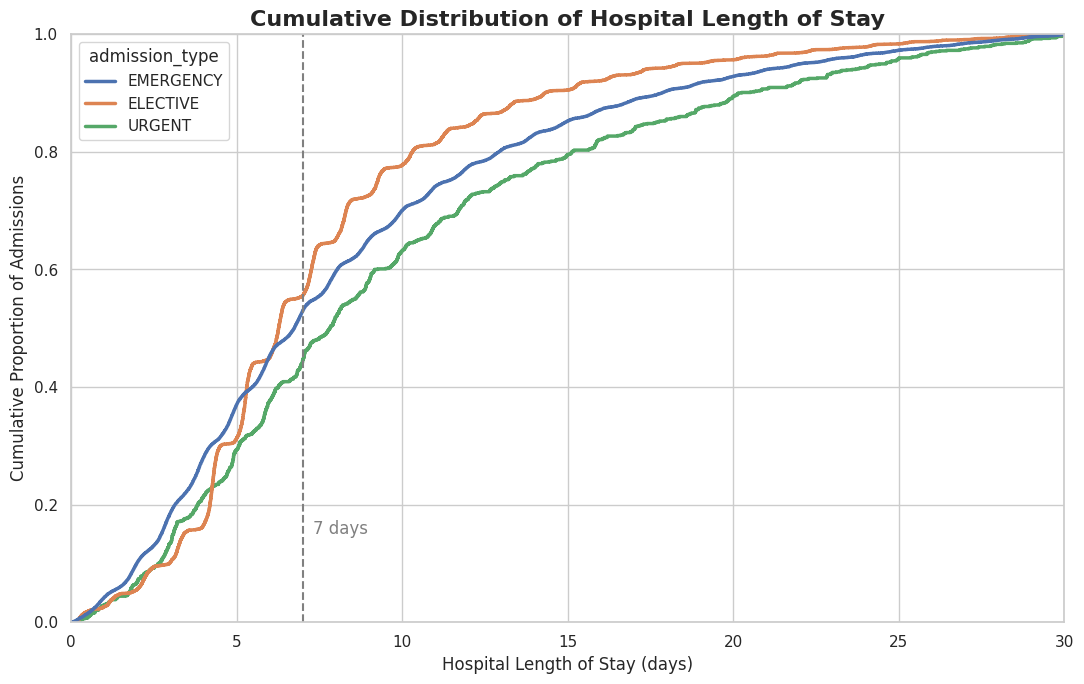

In [ ]:
# VISUALIZATION 1
# Empirical cumulative distribution function (ECDF) of Hospital Length of Stay by Admission Type
# Tells us at any number of hospital days X, what proportion of admissions have a length of stay at or below X?

# Adults only; restrict extreme long stays so the main
# distribution remains readable.
ecdf_df = adm[
    (adm["age"] >= 18)
    & (adm["hospital_los_days"].between(0, 30))
].copy()

# Use the four most common admission types
top_types = (
    ecdf_df["admission_type"]
    .value_counts()
    .head(4)
    .index
)

ecdf_df = ecdf_df[
    ecdf_df["admission_type"].isin(top_types)
]

plt.figure(figsize=(11, 7))

sns.ecdfplot(
    data=ecdf_df,
    x="hospital_los_days",
    hue="admission_type",
    linewidth=2.5
)

# Reference line for one week
plt.axvline(
    7,
    linestyle="--",
    linewidth=1.5,
    color="gray"
)

plt.text(
    7.3,
    0.15,
    "7 days",
    color="gray"
)

plt.title(
    "Cumulative Distribution of Hospital Length of Stay",
    fontsize=16,
    weight="bold"
)
plt.xlabel("Hospital Length of Stay (days)")
plt.ylabel("Cumulative Proportion of Admissions")
plt.xlim(0, 30)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

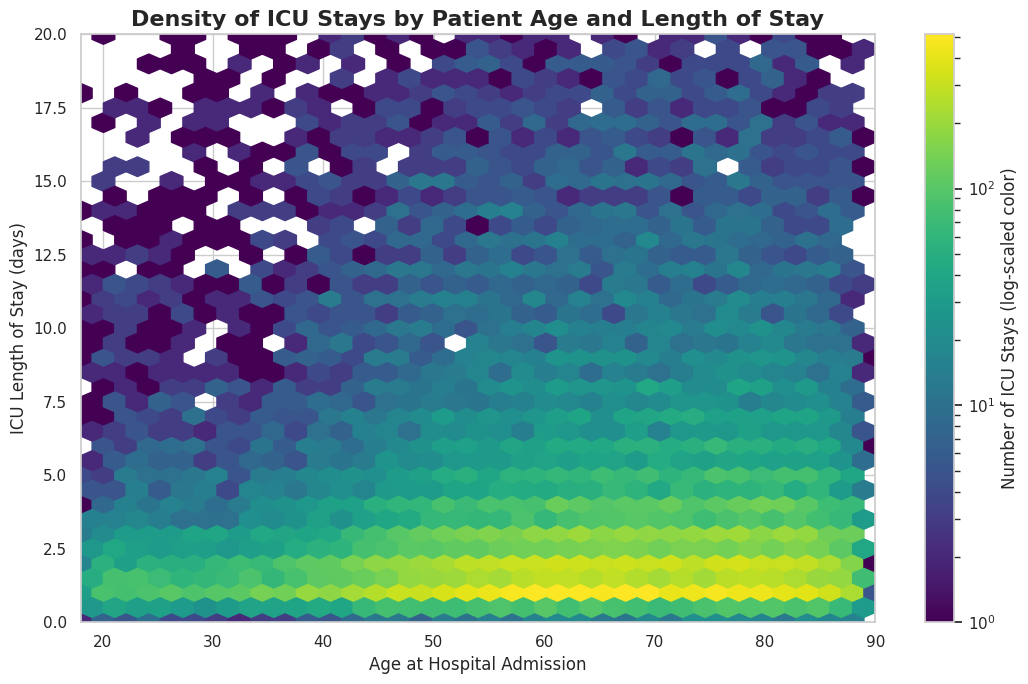

In [ ]:
# VISUALIZATION 2
# Hexbin Density: Age vs ICU Length of Stay

hex_df = icu[
    (icu["age"] >= 18)
    & (icu["age"] <= 90)
    & (icu["icu_los_days"].between(0, 20))
].dropna(
    subset=["age", "icu_los_days"]
)

plt.figure(figsize=(11, 7))

hb = plt.hexbin(
    hex_df["age"],
    hex_df["icu_los_days"],
    gridsize=35,
    mincnt=1,
    bins="log",
    cmap="viridis"
)

cbar = plt.colorbar(hb)
cbar.set_label(
    "Number of ICU Stays (log-scaled color)"
)

plt.title(
    "Density of ICU Stays by Patient Age and Length of Stay",
    fontsize=16,
    weight="bold"
)
plt.xlabel("Age at Hospital Admission")
plt.ylabel("ICU Length of Stay (days)")
plt.xlim(18, 90)
plt.ylim(0, 20)

plt.tight_layout()
plt.show()

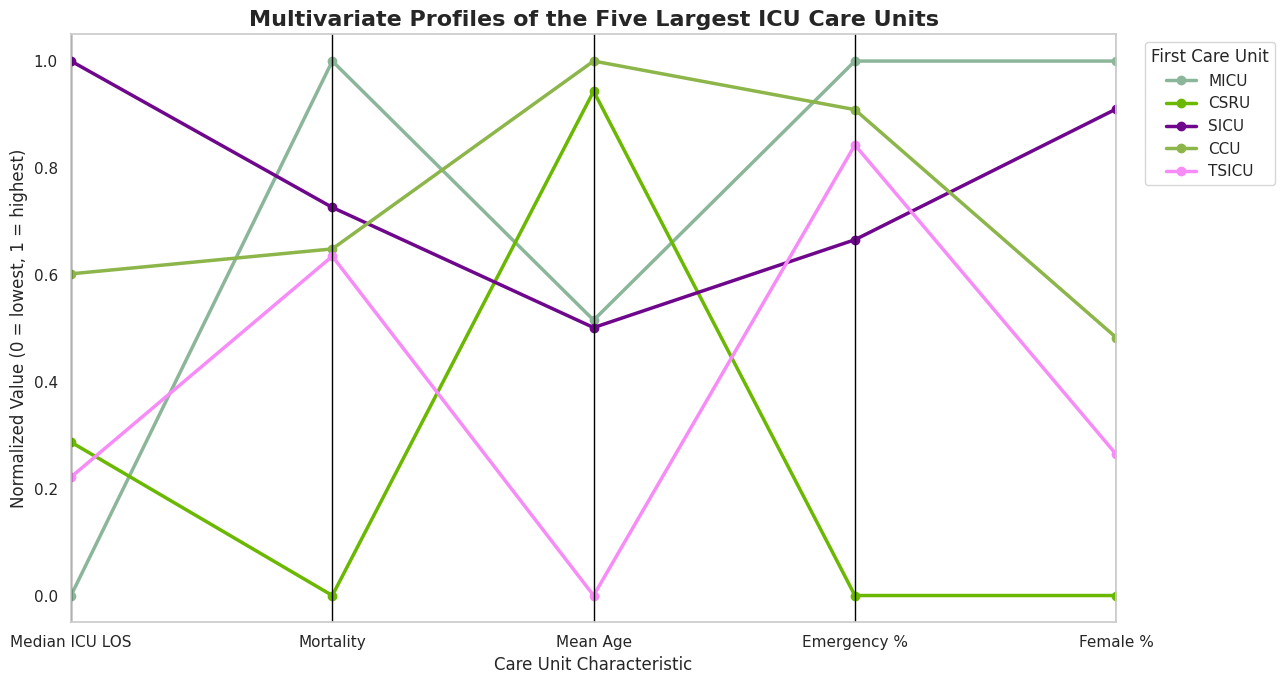

In [ ]:
# VISUALIZATION 3
# Parallel Coordinates: ICU Care Unit Profiles


from pandas.plotting import parallel_coordinates

care_df = icu[
    (icu["age"] >= 18)
    & icu["first_careunit"].notna()
].copy()

# Summarize each ICU care unit
care_profile = (
    care_df
    .groupby("first_careunit")
    .agg(
        n_stays=("icustay_id", "nunique"),

        median_icu_los=(
            "icu_los_days", "median"
        ),

        mortality_rate=(
            "hospital_expire_flag", "mean"
        ),

        mean_age=(
            "age", "mean"
        ),

        emergency_rate=(
            "admission_type",
            lambda x: (x == "EMERGENCY").mean()
        ),

        female_rate=(
            "gender",
            lambda x: (x == "F").mean()
        )
    )
    .reset_index()
)

# Keep the five care units with the most ICU stays
care_profile = (
    care_profile
    .nlargest(5, "n_stays")
    .copy()
)

metrics = [
    "median_icu_los",
    "mortality_rate",
    "mean_age",
    "emergency_rate",
    "female_rate"
]

# Min-max normalize each metric to [0, 1]
normalized = care_profile[
    ["first_careunit"] + metrics
].copy()

for column in metrics:
    minimum = normalized[column].min()
    maximum = normalized[column].max()

    if maximum > minimum:
        normalized[column] = (
            normalized[column] - minimum
        ) / (maximum - minimum)
    else:
        normalized[column] = 0

# Friendly labels
normalized = normalized.rename(
    columns={
        "median_icu_los": "Median ICU LOS",
        "mortality_rate": "Mortality",
        "mean_age": "Mean Age",
        "emergency_rate": "Emergency %",
        "female_rate": "Female %"
    }
)

plot_metrics = [
    "Median ICU LOS",
    "Mortality",
    "Mean Age",
    "Emergency %",
    "Female %"
]

plt.figure(figsize=(13, 7))

parallel_coordinates(
    normalized,
    class_column="first_careunit",
    cols=plot_metrics,
    linewidth=2.5,
    marker="o",
    markersize=6
)

plt.title(
    "Multivariate Profiles of the Five Largest ICU Care Units",
    fontsize=16,
    weight="bold"
)

plt.ylabel(
    "Normalized Value (0 = lowest, 1 = highest)"
)
plt.xlabel("Care Unit Characteristic")
plt.legend(
    title="First Care Unit",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

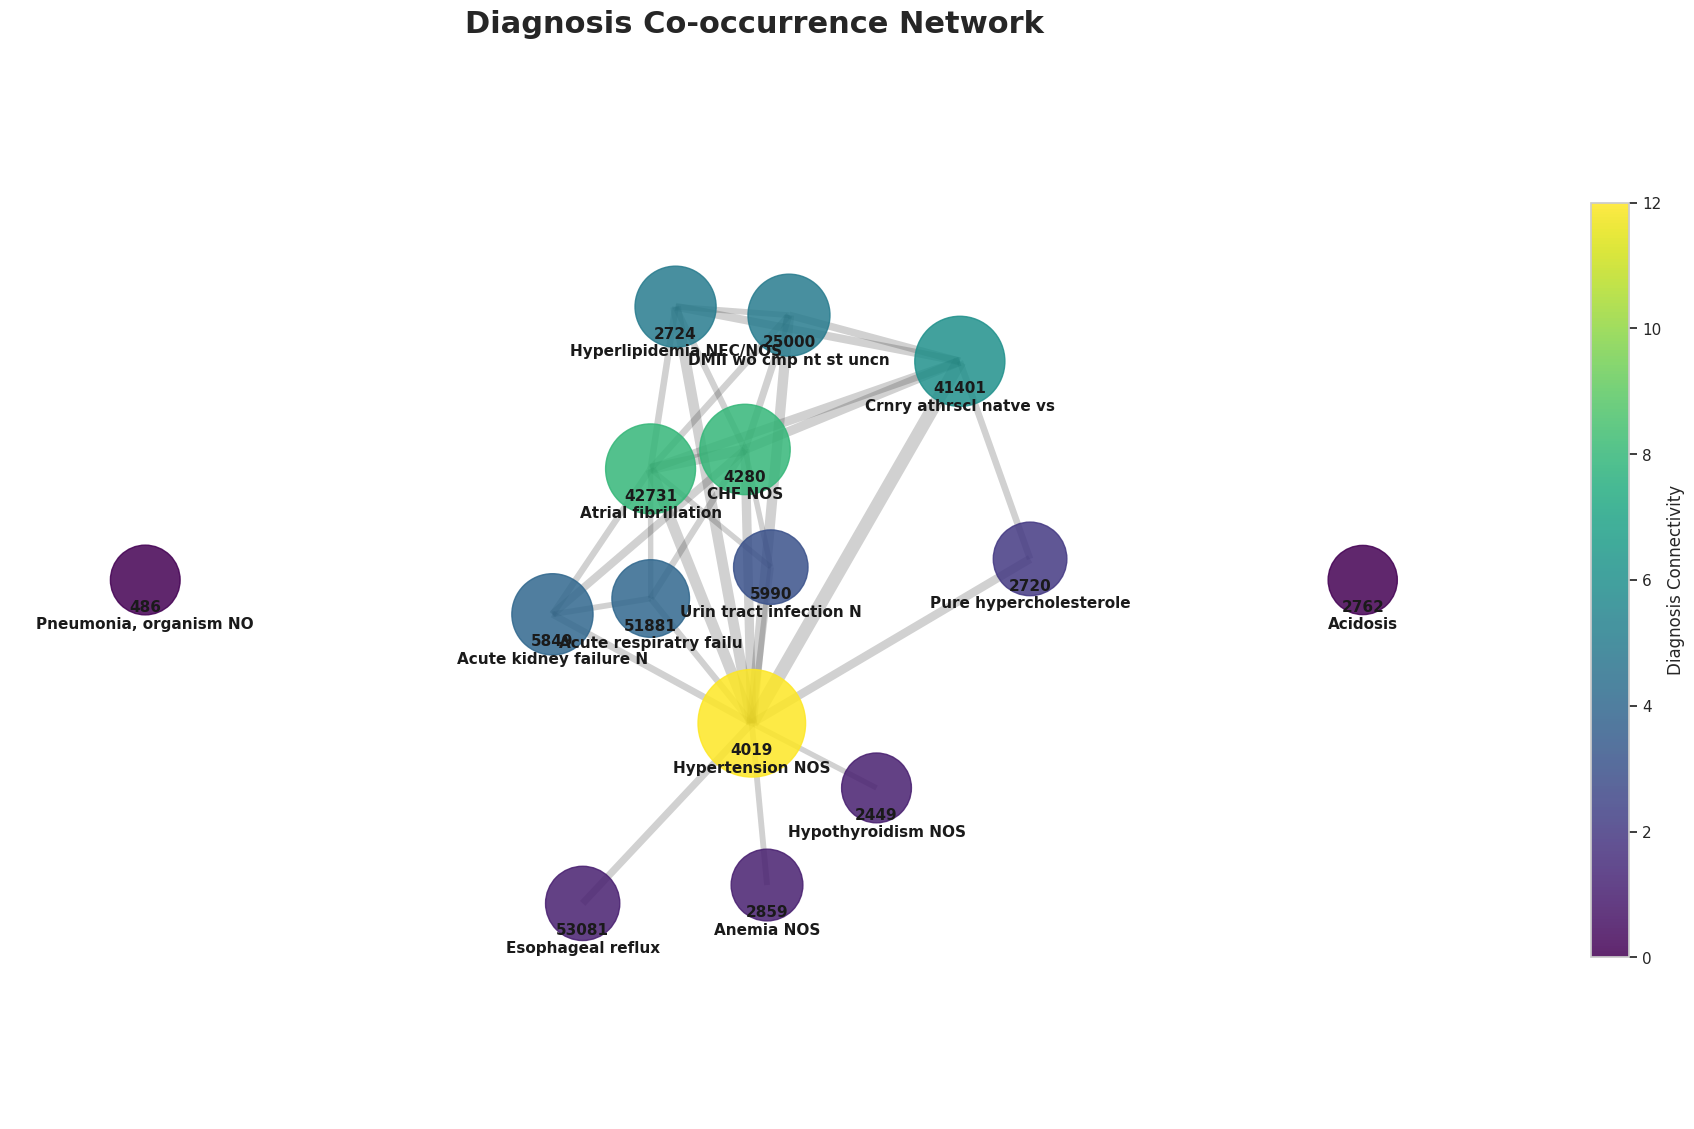

In [ ]:
# VISUALIZATION 4
# Diagnosis Co-occurrence Network

import networkx as nx
from itertools import combinations
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# Ensure diagnosis codes are strings
diagnoses["icd9_code"] = diagnoses["icd9_code"].astype(str).str.strip()
diagnoses_labels["icd9_code"] = diagnoses_labels["icd9_code"].astype(str).str.strip()

# Keep adult hospital admissions only
adult_hadm_ids = set(adm.loc[adm["age"] >= 18, "hadm_id"].dropna())
diag = diagnoses[diagnoses["hadm_id"].isin(adult_hadm_ids)][["hadm_id", "icd9_code"]].dropna().drop_duplicates()

# Frequency and top codes
diagnosis_frequency = diag.groupby("icd9_code")["hadm_id"].nunique().sort_values(ascending=False)
top_codes = diagnosis_frequency.head(15).index.tolist()
top_diag = diag[diag["icd9_code"].isin(top_codes)]

# Pair counts for edges
pair_counts = Counter()
for hadm_id, group in top_diag.groupby("hadm_id"):
    codes = sorted(group["icd9_code"].unique())
    for pair in combinations(codes, 2):
        pair_counts[pair] += 1
top_edges = pair_counts.most_common(30)

# Construct network
G = nx.Graph()
for code in top_codes:
    G.add_node(code, frequency=diagnosis_frequency[code])
for (code1, code2), weight in top_edges:
    G.add_edge(code1, code2, weight=weight)

# Labels
label_dictionary = diagnoses_labels.drop_duplicates("icd9_code").set_index("icd9_code")["short_title"].to_dict()
labels = {code: f"{code}\n{str(label_dictionary.get(code, 'Unknown'))[:22]}" for code in G.nodes}

# Node/Edge Styling
max_freq = max(diagnosis_frequency[c] for c in G.nodes)
node_sizes = [1500 + 4500 * diagnosis_frequency[n] / max_freq for n in G.nodes]
node_colors = [G.degree(n) for n in G.nodes]
max_w = max(d['weight'] for u, v, d in G.edges(data=True))
edge_widths = [1.5 + 8 * d['weight'] / max_w for u, v, d in G.edges(data=True)]

# SPATIAL PARTITIONING & OVERLAP FIX
isolated_nodes = [n for n, d in G.degree() if d == 0]
connected_nodes = [n for n in G.nodes if n not in isolated_nodes]
connected_subgraph = G.subgraph(connected_nodes)

# 1. Use Kamada-Kawai layout for the main cluster
pos_connected = nx.kamada_kawai_layout(connected_subgraph)

# 2. Scale the connected subgraph coordinates to 9.0 for more spread
pos = {node: [coord[0] * 9.0, coord[1] * 9.0] for node, coord in pos_connected.items()}

# 3. Place isolated nodes far outside the expanded center bounds
for i, node in enumerate(isolated_nodes):
    if i % 2 == 0:
        pos[node] = [-18.0, 0.0]  # Far left
    else:
        pos[node] = [18.0, 0.0]   # Far right

plt.figure(figsize=(24, 14))
ax = plt.gca()

nodes = nx.draw_networkx_nodes(
    G, pos, node_size=node_sizes,
    node_color=node_colors, cmap="viridis", alpha=0.85
)

nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=0.2)

# Label positions with offset adjusted for the new larger scale
label_pos = {k: [v[0], v[1] - 1.0] for k, v in pos.items()}
nx.draw_networkx_labels(
    G, label_pos, labels=labels, font_size=11, font_weight="bold"
)

cbar = plt.colorbar(nodes, shrink=0.7)
cbar.set_label("Diagnosis Connectivity", fontsize=12)

plt.title("Diagnosis Co-occurrence Network", fontsize=22, weight="bold")
plt.axis("off")

# BROAD VIEWPORT FOR EXPANDED LAYOUT
plt.xlim(-22.0, 22.0)
plt.ylim(-15.0, 15.0)

plt.show()

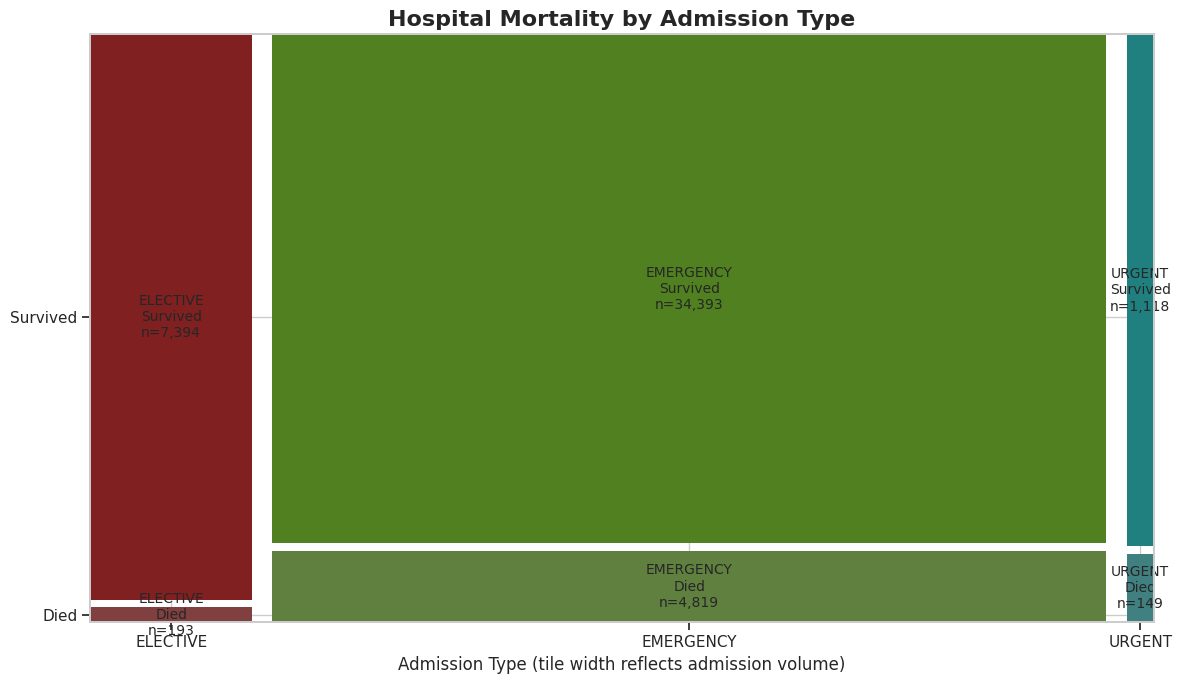

In [ ]:
# VISUALIZATION 5
# Mosaic Plot: Admission Type vs Hospital Mortality

from statsmodels.graphics.mosaicplot import mosaic
import numpy as np # Import numpy for np.where

mosaic_df = adm[
    (adm["age"] >= 18)
    & adm["admission_type"].notna()
    & adm["hospital_expire_flag"].notna()
].copy()

# Use the four most common admission types
top_types = (
    mosaic_df["admission_type"]
    .value_counts()
    .head(4)
    .index
)

mosaic_df = mosaic_df[
    mosaic_df["admission_type"].isin(top_types)
]

# Convert mortality flag to readable labels
mosaic_df["outcome"] = np.where(
    mosaic_df["hospital_expire_flag"] == 1,
    "Died",
    "Survived"
)

# Count each admission type/outcome combination
mosaic_counts = (
    mosaic_df
    .groupby(
        ["admission_type", "outcome"]
    )
    .size()
)

fig, ax = plt.subplots(
    figsize=(12, 7)
)

mosaic(
    mosaic_counts,
    ax=ax,
    gap=0.02,
    labelizer=lambda key:
        f"{key[0]}\n{key[1]}\n"
        f"n={mosaic_counts.get(key, 0):,}" # Use .get() to safely handle missing keys
)

ax.set_title(
    "Hospital Mortality by Admission Type",
    fontsize=16,
    weight="bold"
)

ax.set_xlabel(
    "Admission Type "
    "(tile width reflects admission volume)"
)

plt.tight_layout()
plt.show()

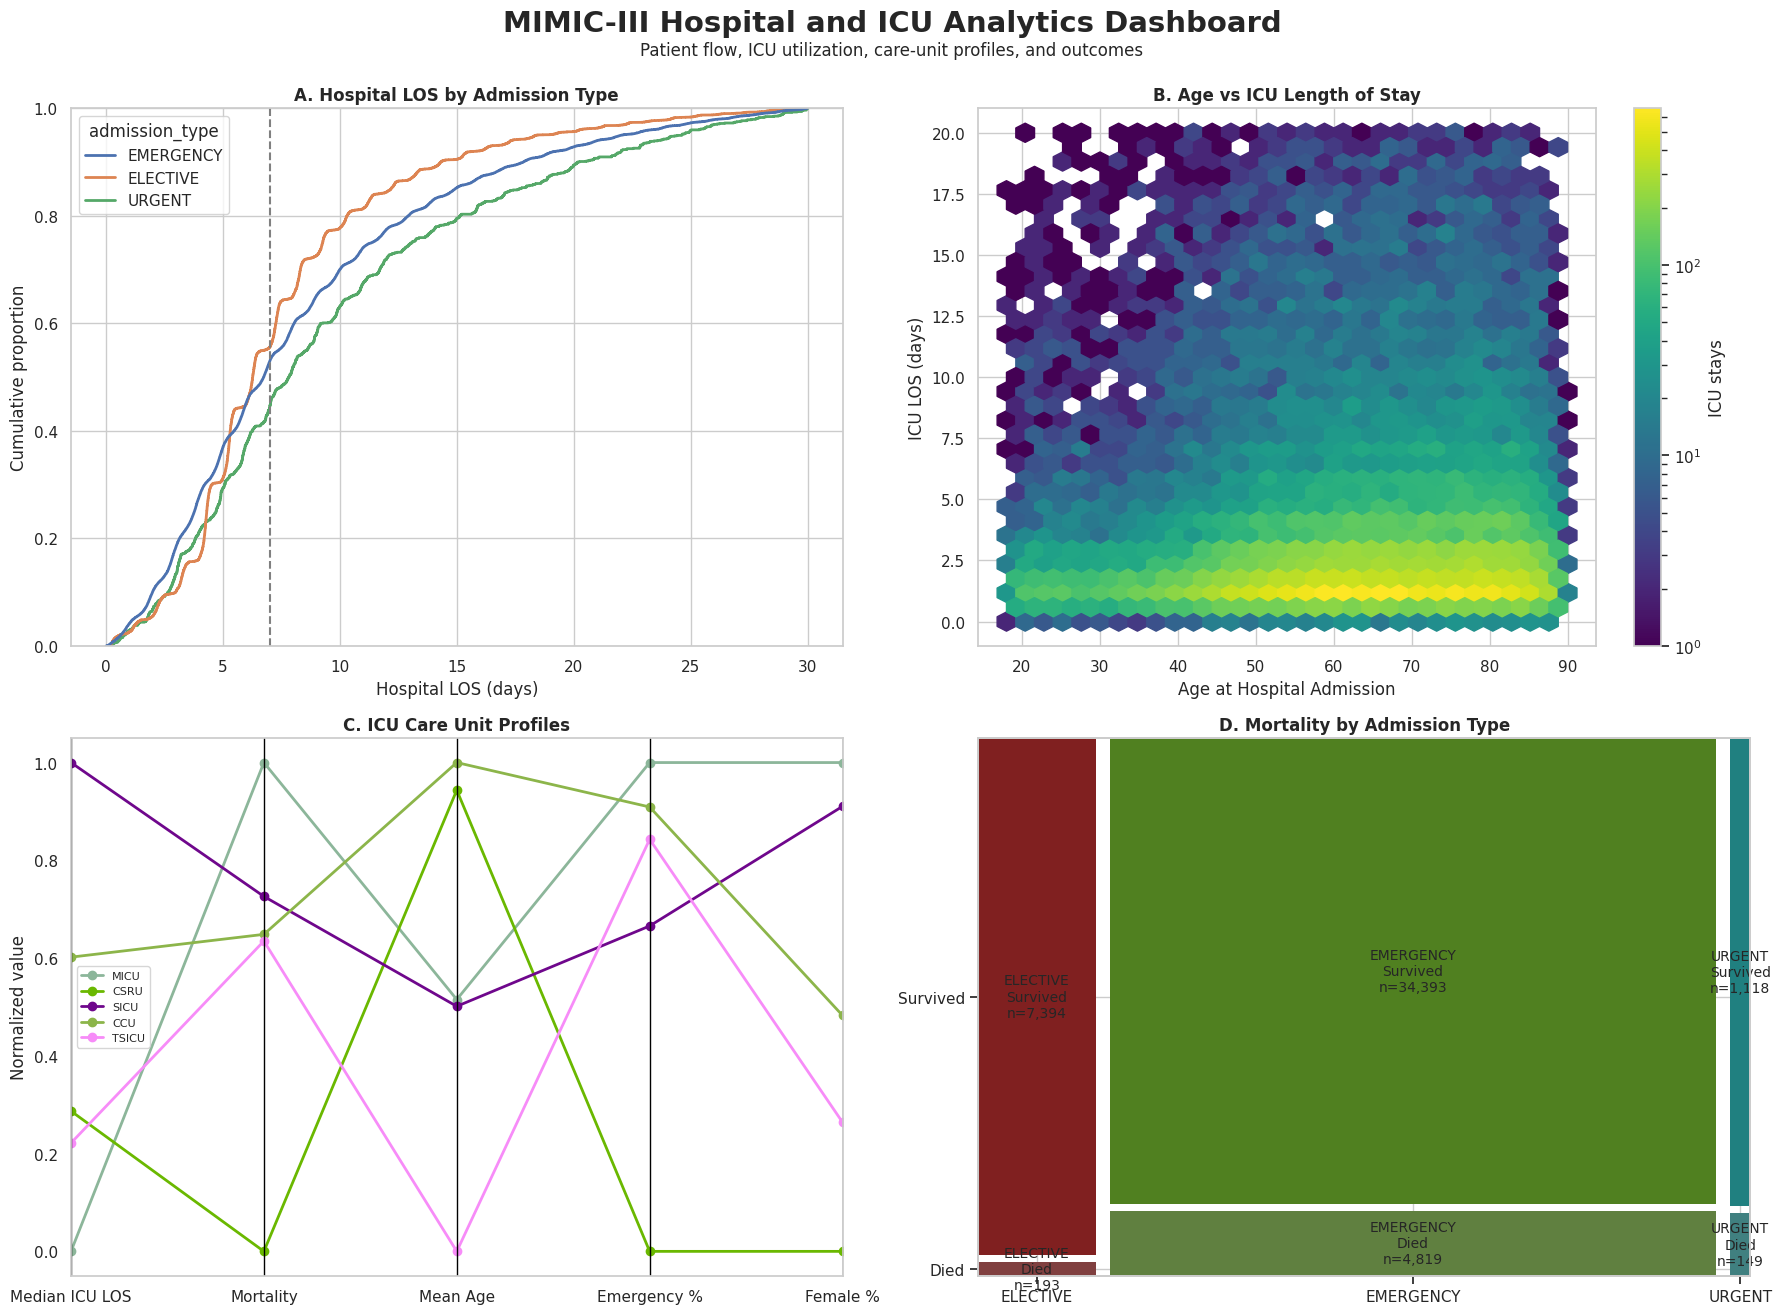

In [ ]:
# BONUS: MIMIC-III ICU / HOSPITAL DASHBOARD

from pandas.plotting import parallel_coordinates
from statsmodels.graphics.mosaicplot import mosaic

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 13)
)

# Panel A: ECDF
sns.ecdfplot(
    data=ecdf_df,
    x="hospital_los_days",
    hue="admission_type",
    linewidth=2,
    ax=axes[0, 0]
)

axes[0, 0].axvline(
    7,
    linestyle="--",
    color="gray"
)

axes[0, 0].set_title(
    "A. Hospital LOS by Admission Type",
    weight="bold"
)

axes[0, 0].set_xlabel(
    "Hospital LOS (days)"
)

axes[0, 0].set_ylabel(
    "Cumulative proportion"
)

# Panel B: Hexbin
hb = axes[0, 1].hexbin(
    hex_df["age"],
    hex_df["icu_los_days"],
    gridsize=30,
    mincnt=1,
    bins="log",
    cmap="viridis"
)

fig.colorbar(
    hb,
    ax=axes[0, 1],
    label="ICU stays"
)

axes[0, 1].set_title(
    "B. Age vs ICU Length of Stay",
    weight="bold"
)

axes[0, 1].set_xlabel(
    "Age at Hospital Admission"
)

axes[0, 1].set_ylabel(
    "ICU LOS (days)"
)

# Panel C: Parallel coordinates
parallel_coordinates(
    normalized,
    class_column="first_careunit",
    cols=plot_metrics,
    linewidth=2,
    marker="o",
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "C. ICU Care Unit Profiles",
    weight="bold"
)

axes[1, 0].set_ylabel(
    "Normalized value"
)

axes[1, 0].legend(
    fontsize=8
)

# Panel D: Mosaic with numerical values
mosaic(
    mosaic_counts,
    ax=axes[1, 1],
    gap=0.02,
    labelizer=lambda key:
        f"{key[0]}\n{key[1]}\nn={mosaic_counts.get(key, 0):,}"
)

axes[1, 1].set_title(
    "D. Mortality by Admission Type",
    weight="bold"
)

# Dashboard title
fig.suptitle(
    "MIMIC-III Hospital and ICU Analytics Dashboard",
    fontsize=21,
    weight="bold",
    y=1.01
)

# Subtitle
fig.text(
    0.5, 0.975,
    "Patient flow, ICU utilization, care-unit profiles, and outcomes",
    ha="center",
    fontsize=12
)

plt.tight_layout()
plt.show()